# Beef direction prediction

This notebook asks whether weather before slaughter helps predict an above- or below-reference outcome for live weight, carcass weight and indicative price. Each observation is a group of animals of the same type and teeth count slaughtered on the same date. The reference comes from training dates for animals of the same type and teeth count.

The overview compares steers and heifers. The weather interpretation focuses on steer elastic net, using the target-specific horizons set in the ablation cell. The notebook uses the completed run in `results/beef_direction_comparison_10fold`, writes tables to `results/beef_direction_analysis_10fold`, and saves figures to `figs/beef_direction_modelling_10fold`.

In [1]:
from pathlib import Path
import hashlib
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

ROOT = Path.cwd()
RESULTS = ROOT / "results/beef_direction_comparison_10fold"
assert RESULTS.exists(), "Run this notebook from the repository directory."
ANALYSIS = ROOT / "results/beef_direction_analysis_10fold"
FIGS = ROOT / "figs/beef_direction_modelling_10fold"
ANALYSIS.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)
TARGETS = ["live weight", "carcass weight", "price"]
TITLES = ["Live weight", "Carcass weight", "Indicative price"]
ANIMALS = ["steer", "heifer"]
MODELS = ["ElasticNet", "RandomForest", "ExtraTrees", "LightGBM", "HistGradientBoosting"]
MODEL_NAMES = dict(zip(MODELS, ["Elastic net", "Random forest", "Extra trees", "LightGBM", "Hist. boosting"]))
HORIZONS = [30, 60, 120, 180]

plt.rcParams.update({
    "font.family": "serif",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.title_fontsize": 12,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "legend.frameon": False,
    "figure.figsize": (9, 3)  # standard size for subplots
})
COLORS = ['#5F6F52', '#A9B388', '#B99470']
COLORS2 = ['#395144', '#4E6C50', '#AA8B56']
PALETTE = {"steer": COLORS[2], "heifer": COLORS[0]}
MODEL_COLORS = dict(zip(MODELS, [*COLORS, COLORS2[0], COLORS2[2]]))
MODEL_STYLES = dict(zip(MODELS, ["-", "--", "-.", ":", "--"]))

def save(fig, name):
    FIGS.mkdir(parents=True, exist_ok=True)
    for ext in ["svg", "png"]:
        fig.savefig(FIGS / f"{name}.{ext}", dpi=300, bbox_inches="tight")

def tidy(ax):
    ax.spines[["top", "right"]].set_visible(False)

def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

## Performance

AUC is calculated within folds and combined using date-pair weights. Significant-group scores use the same predictions. Missing AUC means insufficient class support.

In [2]:
status = json.loads((RESULTS / "run_status.json").read_text())
manifest = json.loads((RESULTS / "run_manifest.json").read_text())
results = pd.read_csv(RESULTS / "result_table.csv", float_precision="round_trip")
folds = pd.read_csv(RESULTS / "fold_scores.csv", float_precision="round_trip")
overall = results.loc[results["slice"].eq("overall")].copy()
weather = overall.loc[overall.setting.eq("weather_pruned")].copy()
baselines = overall.loc[overall.setting.ne("weather_pruned")].copy()
metrics = ["auc_all", "auc_significant", "log_loss_all", "brier_score_all",
           "contributing_folds_all", "contributing_groups_all", "contributing_dates_all",
           "contributing_folds_significant", "contributing_groups_significant", "contributing_dates_significant"]
performance = overall.set_index(["animal_type", "target", "model", "setting", "horizon"])[metrics].rename(index={"Dummy": "Baseline"}, level="model").sort_index()
ANALYSIS.mkdir(parents=True, exist_ok=True)
performance.to_csv(ANALYSIS / "performance_table.csv")
performance.to_latex(ANALYSIS / "performance_table.tex", float_format="%.3f", na_rep="--", longtable=True,
                     caption="Within-fold date-pair-weighted AUC for every fixed model and horizon, with contributing counts. Significant-shift results reuse the same predictions.",
                     label="tab:beef:direction_all")
support_columns = ["evaluated_groups_all", "evaluated_dates_all", "contributing_folds_all", "contributing_groups_all",
                   "contributing_dates_all", "evaluated_groups_significant", "contributing_folds_significant",
                   "contributing_groups_significant", "contributing_dates_significant"]
support = weather.drop_duplicates(["animal_type", "target"]).set_index(["animal_type", "target"])[support_columns]
support.to_csv(ANALYSIS / "evaluation_support.csv")

In [3]:
beef = pd.read_csv(RESULTS / "inputs" / "beef_preprocessed.csv")

group_sd = beef.groupby(["Animal Type", "kill date", "Teeth"])[TARGETS].std()
mean_sd = group_sd.groupby(level="Animal Type").mean()
n_groups = group_sd.groupby(level="Animal Type").count()

table = pd.concat({"Mean within-group SD": mean_sd, "Groups used": n_groups}, axis=1)
table = table.rename(columns=dict(zip(TARGETS, TITLES)), level=1)
display(table.style.format(precision=2))

Mean within-group SD 
 Groups used 
 
 
   
 Live weight 
 Carcass weight 
 Indicative price 
 Live weight 
 Carcass weight 
 Indicative price 
 
 
 Animal Type 
   
   
   
   
   
   
 
 
 
 
 cow 
 65.40 
 32.86 
 118.38 
 3 
 3 
 3 
 
 
 heifer 
 22.30 
 12.91 
 72.67 
 22 
 22 
 22 
 
 
 steer 
 26.41 
 15.24 
 88.89 
 49 
 49 
 49

In [4]:
predictors = ["Teeth", "Teeth + NZDI", *[f"{h} days" for h in HORIZONS]]
subsets = {"auc_all": "All groups", "auc_significant": "Significant groups"}

sub = overall.loc[overall["model"].isin(MODELS)].copy()
sub["Predictors"] = sub["setting"].map({
    "controls": "Teeth",
    "nzdi": "Teeth + NZDI",
})
mask = sub["setting"].eq("weather_pruned")
sub.loc[mask, "Predictors"] = (
    sub.loc[mask, "horizon"].astype(int).astype(str) + " days"
)
sub = sub.dropna(subset=["Predictors"])

index = pd.MultiIndex.from_product(
    [ANIMALS, TARGETS, MODELS], names=["Animal", "Target", "Model"]
)
table = pd.concat({
    label: sub.pivot(
        index=["animal_type", "target", "model"],
        columns="Predictors",
        values=metric,
    ).reindex(index=index, columns=predictors)
    for metric, label in subsets.items()
}, axis=1).round(3)

# Highlight ties at the displayed precision.
bold = pd.DataFrame(False, index=table.index, columns=table.columns)
underline = bold.copy()

for label in subsets.values():
    values = table[label]
    bold[label] = values.eq(values.max(axis=1), axis=0)
    best = values.max(axis=1).groupby(level=["Animal", "Target"]).transform("max")
    underline[label] = values.eq(best, axis=0)

pretty = (
    table.rename(index={a: a.capitalize() for a in ANIMALS}, level="Animal")
    .rename(index=dict(zip(TARGETS, TITLES)), level="Target")
    .rename(index=MODEL_NAMES, level="Model")
)
styles = pd.DataFrame("", index=table.index, columns=table.columns)
styles = styles.mask(bold, "font-weight: bold;")
styles += underline.map(lambda x: "text-decoration: underline;" if x else "")
styles.index = pretty.index

display(
    pretty.style
    .format("{:.3f}", na_rep="—")
    .apply(lambda _: styles, axis=None)
    .set_table_styles([
        {"selector": "th, td", "props": [
            ("font-family", "sans-serif"), ("padding", "4px 7px"),
        ]},
        {"selector": "th.col_heading", "props": [("text-align", "center")]},
        {"selector": "th.row_heading.level0, th.row_heading.level1", "props": [
            ("writing-mode", "vertical-rl"),
            ("transform", "rotate(180deg)"),
            ("text-align", "center"),
            ("vertical-align", "middle"),
        ]},
    ])
)
ANALYSIS.mkdir(parents=True, exist_ok=True)
pretty.to_csv(ANALYSIS / "auc_comparison.csv")

# LaTeX export: requires booktabs, multirow and graphicx.
n = len(predictors)
lines = [
    r"\begin{table*}[t]",
    r"\centering",
    r"\caption{Classification AUC. Horizon columns include teeth, NZDI and "
    r"weather. Bold indicates the best setting within each model; underlining "
    r"indicates the best across models within each animal, target and evaluation "
    r"subset. Ties at three decimal places are highlighted equally.}",
    r"\label{tab:beef:direction_comparison}",
    r"\scriptsize",
    r"\setlength{\tabcolsep}{3pt}",
    r"\resizebox{\textwidth}{!}{%",
    r"\begin{tabular}{lll" + "r" * (2 * n) + "}",
    r"\toprule",
    r" & & & \multicolumn{%d}{c}{All groups}"
    r" & \multicolumn{%d}{c}{Significant groups} \\" % (n, n),
    r"\cmidrule(lr){4-%d}\cmidrule(lr){%d-%d}" % (3+n, 4+n, 3+2*n),
    "Animal & Target & Model & " + " & ".join(predictors * 2) + r" \\",
    r"\midrule",
]

for animal in ANIMALS:
    for target_i, (target, title) in enumerate(zip(TARGETS, TITLES)):
        for model_i, model in enumerate(MODELS):
            key = (animal, target, model)
            animal_label = (
                r"\multirow{%d}{*}{\rotatebox{90}{%s}}"
                % (len(TARGETS) * len(MODELS), animal.capitalize())
                if target_i == 0 and model_i == 0 else ""
            )
            target_label = (
                r"\multirow{%d}{*}{\rotatebox{90}{%s}}"
                % (len(MODELS), title)
                if model_i == 0 else ""
            )

            values = []
            for column in table.columns:
                value = table.loc[key, column]
                text = "--" if pd.isna(value) else f"{value:.3f}"
                if bold.loc[key, column]:
                    text = r"\textbf{" + text + "}"
                if underline.loc[key, column]:
                    text = r"\underline{" + text + "}"
                values.append(text)

            lines.append(
                " & ".join([
                    animal_label, target_label, MODEL_NAMES[model], *values
                ]) + r" \\"
            )

        if target_i < len(TARGETS) - 1:
            lines.append(r"\cmidrule(lr){2-%d}" % (3 + 2*n))

    if animal != ANIMALS[-1]:
        lines.append(r"\midrule")

lines += [
    r"\bottomrule",
    r"\end{tabular}%",
    r"}",
    r"\end{table*}",
]
(ANALYSIS / "auc_comparison.tex").write_text(
    "\n".join(lines), encoding="utf-8"
)

All groups 
 Significant groups 
 
 
   
   
 Predictors 
 Teeth 
 Teeth + NZDI 
 30 days 
 60 days 
 120 days 
 180 days 
 Teeth 
 Teeth + NZDI 
 30 days 
 60 days 
 120 days 
 180 days 
 
 
 Animal 
 Target 
 Model 
   
   
   
   
   
   
   
   
   
   
   
   
 
 
 
 
 Steer 
 Live weight 
 Elastic net 
 0.460 
 0.540 
 0.568 
 0.540 
 0.498 
 0.577 
 0.500 
 0.786 
 0.714 
 0.714 
 0.714 
 0.571 
 
 
 Random forest 
 0.517 
 0.528 
 0.470 
 0.408 
 0.418 
 0.465 
 0.357 
 0.714 
 0.571 
 0.571 
 0.429 
 0.571 
 
 
 Extra trees 
 0.492 
 0.377 
 0.407 
 0.436 
 0.386 
 0.343 
 0.357 
 0.179 
 0.429 
 0.500 
 0.286 
 0.286 
 
 
 LightGBM 
 0.492 
 0.415 
 0.442 
 0.483 
 0.320 
 0.442 
 0.357 
 0.536 
 0.571 
 0.571 
 0.429 
 0.536 
 
 
 Hist. boosting 
 0.455 
 0.336 
 0.427 
 0.442 
 0.320 
 0.352 
 0.357 
 0.464 
 0.643 
 0.571 
 0.250 
 0.464 
 
 
 Carcass weight 
 Elastic net 
 0.500 
 0.593 
 0.927 
 0.877 
 0.894 
 0.894 
 0.536 
 0.643 
 0.857 
 0.857 
 0.857 
 0.857 
 
 
 Random forest 
 0.440 
 0.566 
 0.656 
 0.691 
 0.742 
 0.716 
 0.518 
 0.571 
 0.429 
 0.429 
 0.821 
 0.857 
 
 
 Extra trees 
 0.410 
 0.568 
 0.781 
 0.782 
 0.787 
 0.792 
 0.518 
 0.643 
 0.714 
 0.750 
 0.821 
 0.857 
 
 
 LightGBM 
 0.397 
 0.560 
 0.624 
 0.723 
 0.674 
 0.609 
 0.518 
 0.429 
 0.750 
 0.857 
 0.857 
 0.714 
 
 
 Hist. boosting 
 0.397 
 0.546 
 0.675 
 0.640 
 0.634 
 0.658 
 0.518 
 0.429 
 0.571 
 0.571 
 0.714 
 0.714 
 
 
 Indicative price 
 Elastic net 
 0.483 
 0.659 
 0.814 
 0.805 
 0.834 
 0.823 
 0.469 
 0.812 
 0.750 
 0.750 
 0.875 
 0.875 
 
 
 Random forest 
 0.372 
 0.556 
 0.607 
 0.661 
 0.764 
 0.752 
 0.391 
 0.750 
 0.500 
 0.625 
 0.719 
 0.750 
 
 
 Extra trees 
 0.349 
 0.535 
 0.661 
 0.741 
 0.794 
 0.834 
 0.391 
 0.812 
 0.625 
 0.656 
 0.844 
 0.875 
 
 
 LightGBM 
 0.349 
 0.563 
 0.599 
 0.661 
 0.706 
 0.624 
 0.391 
 0.500 
 0.625 
 0.750 
 0.875 
 0.750 
 
 
 Hist. boosting 
 0.349 
 0.588 
 0.592 
 0.663 
 0.813 
 0.748 
 0.391 
 0.625 
 0.500 
 0.625 
 0.750 
 0.750 
 
 
 Heifer 
 Live weight 
 Elastic net 
 0.500 
 0.582 
 0.909 
 0.745 
 1.000 
 1.000 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 Random forest 
 0.782 
 0.891 
 0.836 
 0.818 
 0.836 
 0.836 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 Extra trees 
 0.782 
 1.000 
 0.836 
 0.836 
 0.836 
 0.836 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 LightGBM 
 0.782 
 0.873 
 0.836 
 0.836 
 1.000 
 1.000 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 Hist. boosting 
 0.782 
 0.873 
 0.800 
 0.800 
 0.836 
 0.836 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 Carcass weight 
 Elastic net 
 0.361 
 0.500 
 0.438 
 0.418 
 0.438 
 0.418 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 Random forest 
 0.649 
 0.412 
 0.325 
 0.392 
 0.366 
 0.309 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 Extra trees 
 0.546 
 0.557 
 0.351 
 0.412 
 0.309 
 0.464 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 LightGBM 
 0.526 
 0.345 
 0.412 
 0.387 
 0.366 
 0.366 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 Hist. boosting 
 0.526 
 0.366 
 0.258 
 0.320 
 0.320 
 0.320 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 Indicative price 
 Elastic net 
 0.500 
 0.500 
 0.577 
 0.649 
 0.392 
 0.557 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 Random forest 
 0.371 
 0.598 
 0.278 
 0.299 
 0.366 
 0.216 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 Extra trees 
 0.546 
 0.557 
 0.536 
 0.598 
 0.495 
 0.464 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 LightGBM 
 0.526 
 0.485 
 0.552 
 0.526 
 0.505 
 0.505 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 Hist. boosting 
 0.526 
 0.320 
 0.443 
 0.459 
 0.459 
 0.459 
 — 
 — 
 — 
 — 
 — 
 —

The following figures retain the steer comparison from the previous analysis. The table above includes both animal types.

## Model comparison

All models at their best maximum horizon. Baseline AUC = 0.5.

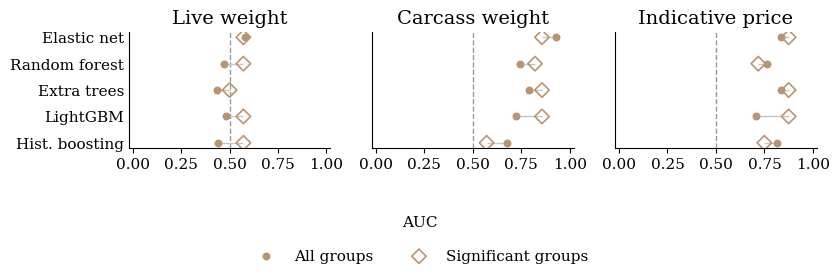

In [5]:
steer = (
    weather.loc[weather.animal_type.eq("steer")]
    .dropna(subset=["auc_all"])
    .sort_values(["auc_all", "horizon"], ascending=[False, True])
    .drop_duplicates(["target", "model"])
)
color = PALETTE["steer"]
y = np.arange(len(MODELS))

fig, axes = plt.subplots(
    1, len(TARGETS), figsize=(8.5, 2.8), sharex=True, sharey=True
)

for ax, target, title in zip(axes, TARGETS, TITLES):
    scores = steer.loc[steer.target.eq(target)].set_index("model").reindex(MODELS)
    all_auc = scores["auc_all"]
    sig_auc = scores["auc_significant"]

    ax.axvline(.5, color="0.6", linestyle="--", linewidth=1)
    ax.hlines(y, all_auc, sig_auc, color="0.78", linewidth=1)
    ax.scatter(all_auc, y, s=22, color=color, label="All groups", zorder=3)
    ax.scatter(sig_auc, y, s=54, marker="D", facecolors="none",
               edgecolors=color, linewidths=1.2, label="Significant groups", zorder=4)

    ax.set(title=title, xlim=(-.02, 1.02), xticks=[0, .25, .5, .75, 1])
    ax.tick_params(axis="y", length=0)
    tidy(ax)

axes[0].set_yticks(y, [MODEL_NAMES[m] for m in MODELS])
axes[0].invert_yaxis()
fig.supxlabel("AUC", fontsize=11, y=.16)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2)
fig.tight_layout(rect=[0, .21, 1, 1])
save(fig, "direction_models_steer_best_horizon")
plt.show()

We retain elastic net for the interpretation plots to compare the same model and horizons across runs.

## Horizon sensitivity

Separate results for each fixed maximum horizon. Model and horizon were not selected inside CV.

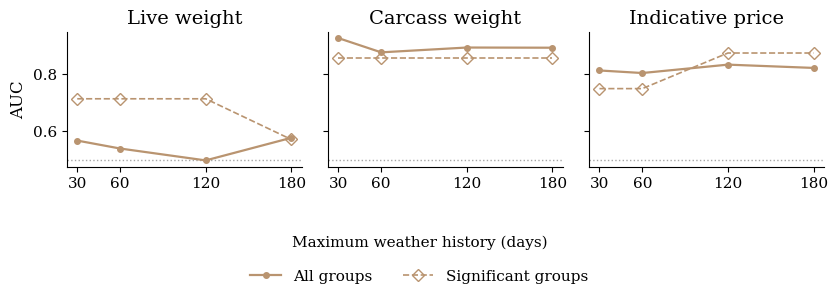

In [6]:
steer_enet = weather.loc[
    weather.animal_type.eq("steer") & weather.model.eq("ElasticNet")
]
color = PALETTE["steer"]

fig, axes = plt.subplots(1, 3, figsize=(8.5, 3), sharex=True, sharey=True)

for ax, target, title in zip(axes, TARGETS, TITLES):
    scores = (
        steer_enet.loc[steer_enet.target.eq(target)]
        .set_index("horizon")
        .reindex(HORIZONS)
    )

    ax.axhline(.5, color="0.65", linestyle=":", linewidth=1)
    ax.plot(HORIZONS, scores["auc_all"], color=color, linewidth=1.6,
            marker="o", markersize=4, label="All groups")
    ax.plot(HORIZONS, scores["auc_significant"], color=color, linewidth=1.2,
            linestyle="--", marker="D", markersize=6, markerfacecolor="none",
            label="Significant groups")

    ax.set(title=title, xticks=HORIZONS), #ylim=(-.03, 1.03),
           #yticks=[0, .25, .5, .75, 1])
    tidy(ax)

axes[0].set_ylabel("AUC")
fig.supxlabel("Maximum weather history (days)", fontsize=11, y=.15)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2)
fig.tight_layout(rect=[0, .20, 1, 1])
save(fig, "direction_horizons_steer_elasticnet")
plt.show()

## Ablation study

AUC gain over the same model using teeth only or teeth + NZDI.

In [7]:
days = {"live weight": 60, "carcass weight": 60, "price": 180}
steer = overall.query("animal_type == 'steer' and model == 'ElasticNet'")
selected = steer.setting.isin(["controls", "nzdi"]) | (steer.setting.eq("weather_pruned") & steer.horizon.eq(steer.target.map(days)))

blocks = {}
for group, metric in [("All groups", "auc_all"), ("Significant groups", "auc_significant")]:
    auc = steer[selected].pivot(index="target", columns="setting", values=metric).loc[TARGETS]
    teeth = auc["controls"]
    gains = auc[["nzdi", "weather_pruned"]].div(teeth.replace(0, np.nan), axis=0).sub(1).mul(100)
    blocks[group] = pd.DataFrame({"Teeth only": teeth, "Teeth+NZDI": gains["nzdi"],
                                  "Teeth+NZDI+Weather": gains["weather_pruned"]})

table = pd.concat(blocks, axis=1)
table.index = pd.MultiIndex.from_arrays([TITLES, [days[t] for t in TARGETS]], names=["Target", "Days"])
ANALYSIS.mkdir(parents=True, exist_ok=True)
table.to_csv(ANALYSIS / "steer_elasticnet_ablation.csv")

fmt = {col: "{:.3f}" if col[1] == "Teeth only" else "{:+.1f}%" for col in table}
display(table.style.format(fmt, na_rep="--"))

caption = ("Steer elastic net ablation. Teeth only reports AUC. The other columns report the percentage "
           "change in AUC relative to teeth only within each evaluation subset. Days gives the maximum "
           "weather history. Significant groups use the same held-out predictions restricted to groups "
           "with significant shifts.")
latex_fmt = {col: spec.replace("%", r"\%") for col, spec in fmt.items()}
table.style.format(latex_fmt, na_rep="--").to_latex(
    ANALYSIS / "steer_elasticnet_ablation.tex", caption=caption, label="tab:steer_elasticnet_ablation",
    hrules=True, multicol_align="c")

All groups 
 Significant groups 
 
 
   
   
 Teeth only 
 Teeth+NZDI 
 Teeth+NZDI+Weather 
 Teeth only 
 Teeth+NZDI 
 Teeth+NZDI+Weather 
 
 
 Target 
 Days 
   
   
   
   
   
   
 
 
 
 
 Live weight 
 60 
 0.460 
 +17.2% 
 +17.2% 
 0.500 
 +57.1% 
 +42.9% 
 
 
 Carcass weight 
 60 
 0.500 
 +18.5% 
 +75.5% 
 0.536 
 +20.0% 
 +60.0% 
 
 
 Indicative price 
 180 
 0.483 
 +36.5% 
 +70.4% 
 0.469 
 +73.3% 
 +86.7%

## Feature importance
Each box summarizes held-out folds with both classes. Boxes show the median and middle 50% of the fold changes, with whiskers spanning the full range. Negative values mean that shuffling reduced AUC.

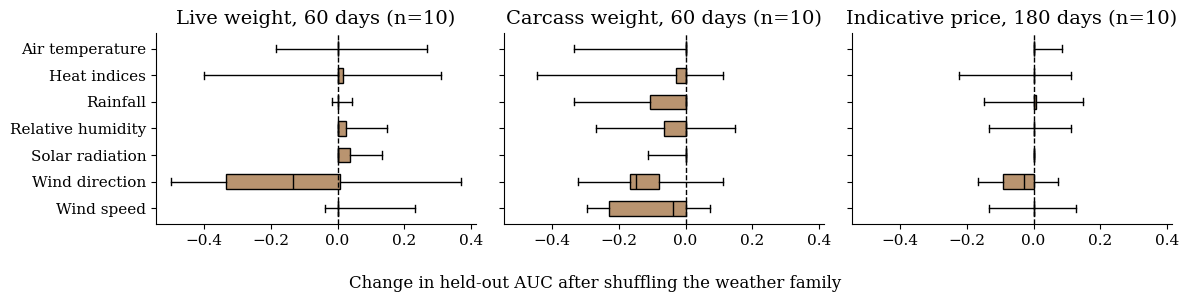

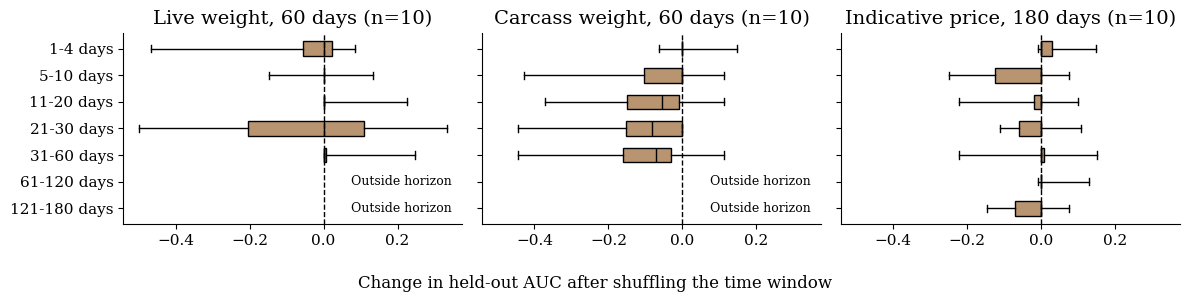

In [8]:
PANEL_TITLES = [f"{title}, {days[t]} days" for title, t in zip(TITLES, TARGETS)]
WINDOW_LABELS = {"0_4": "1-4 days", "5_10": "5-10 days", "11_20": "11-20 days", "21_30": "21-30 days",
                 "31_60": "31-60 days", "61_120": "61-120 days", "121_180": "121-180 days"}

from itertools import permutations
from scipy.special import logit
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

importance_dir = ANALYSIS / "steer_elasticnet"
importance_dir.mkdir(parents=True, exist_ok=True)
families = {"MnTemp(C)": "Air temperature", "MnRH(%)": "Relative humidity", "MnSpd(mps)": "Wind speed",
            "Rain(mm)": "Rainfall", "Average W/m2": "Solar radiation", "RadGlb(MJ/m2)": "Solar radiation"}
changes, coefficients = [], []
for panel, target in enumerate(TARGETS):
    stem = target.replace(" ", "_")
    for fold in range(1, 11):
        fit = json.loads((RESULTS / "fits" / f"steer__{stem}__ElasticNet__weather_pruned__{days[target]}__{fold}.json").read_text())
        coef = {r["feature"].removeprefix("numeric__"): r["coefficient"] for r in fit["coefficients"] if "__win" in r["feature"]}
        coefficients.extend(dict(panel=panel, fold=fold, feature=k, coefficient=v) for k,v in coef.items())
        pred = pd.DataFrame(fit["predictions"])
        w = 1 / pred.groupby("kill date").label.transform("size").to_numpy()
        y = pred.label.to_numpy()
        pair = w[y==1].sum() * w[y==0].sum()
        if not pair:
            continue
        train = pd.read_csv(RESULTS / f"steer_{stem}_fold{fold}_train_labels.csv")
        train = train.loc[train.exclusion.isna()]
        groups = pd.read_csv(RESULTS / f"steer_{stem}_groups.csv").set_index("kill date")
        dates, idx = np.unique(pd.to_datetime(pred["kill date"]).dt.strftime("%Y-%m-%d"), return_inverse=True)
        raw = groups.groupby(level=0).first().loc[dates, list(coef)]
        contribution = StandardScaler().fit(train[list(coef)]).transform(raw) * np.array(list(coef.values()))
        base = logit(pred.probability.to_numpy())
        auc = roc_auc_score(y, base, sample_weight=w)
        # Enumerate all assignments of held-out dates, moving a weather group together.
        for level in ["family", "window"]:
            labels = []
            for feature in coef:
                field, window = feature.split("__win")
                family = families.get(field, "Wind direction" if field.startswith("Wind_") else "Heat indices")
                labels.append(family if level == "family" else WINDOW_LABELS[re.match(r"\d+_\d+",window)[0]])
            candidates = sorted(set(families.values()) | {"Wind direction","Heat indices"}) if level=="family" else [
                v for k,v in WINDOW_LABELS.items() if int(k.split("_")[1]) <= days[target]]
            for group in candidates:
                effect = contribution[:, np.array(labels)==group].sum(axis=1)
                shuffled = [roc_auc_score(y, base + (effect[list(order)]-effect)[idx], sample_weight=w)
                            for order in permutations(range(len(dates)))]
                changes.append([panel,target,days[target],level,group,fold,pair*(auc-np.mean(shuffled)),pair])
frame = pd.DataFrame(changes, columns=["panel","target","horizon","level","group","fold","loss","weight"])
frame["auc_change"] = -frame.loss / frame.weight
importance_summary = frame.groupby(["panel","target","horizon","level","group"])[["loss","weight"]].sum().reset_index()
importance_summary["auc_decrease"] = importance_summary.loss / importance_summary.weight
importance_summary.to_csv(importance_dir / "importance_summary.csv", index=False)
pd.DataFrame(coefficients).to_csv(importance_dir / "importance_coefficients.csv", index=False)

def importance_plot(level, name):
    order = importance_summary.loc[importance_summary.level.eq(level), "group"].unique() if level == "family" else list(WINDOW_LABELS.values())
    fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True, sharex=True)
    for panel, (ax, title) in enumerate(zip(axes, PANEL_TITLES)):
        sub = frame.loc[frame.panel.eq(panel) & frame.level.eq(level)]
        for y, group in enumerate(order):
            values = sub.loc[sub.group.eq(group), "auc_change"].to_numpy()
            if len(values):
                ax.boxplot(values, positions=[y], orientation="horizontal", widths=.55, whis=(0,100),
                           patch_artist=True, boxprops={"facecolor":PALETTE["steer"]},
                           medianprops={"color":"black"}, manage_ticks=False)
            else:
                ax.text(.97, y, "Outside horizon", transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=9)
        ax.axvline(0, color="black", linestyle="--", linewidth=1)
        ax.set_yticks(range(len(order)), order)
        ax.set_title(f"{title} (n={sub.fold.nunique()})")
        tidy(ax)
    axes[0].invert_yaxis()
    label = "weather family" if level == "family" else "time window"
    fig.supxlabel(f"Change in held-out AUC after shuffling the {label}", fontsize=12)
    fig.tight_layout()
    save(fig, name)
    plt.show()

importance_plot("family", "steer_elasticnet_weather_family_importance")
importance_plot("window", "steer_elasticnet_weather_window_importance")

### Coefficient directions
Standardized weather coefficients across the ten training folds. Each panel shows up to 12 features retained in at least half of the folds, ranked by absolute mean coefficient. Boxes show the middle half and whiskers the full range.

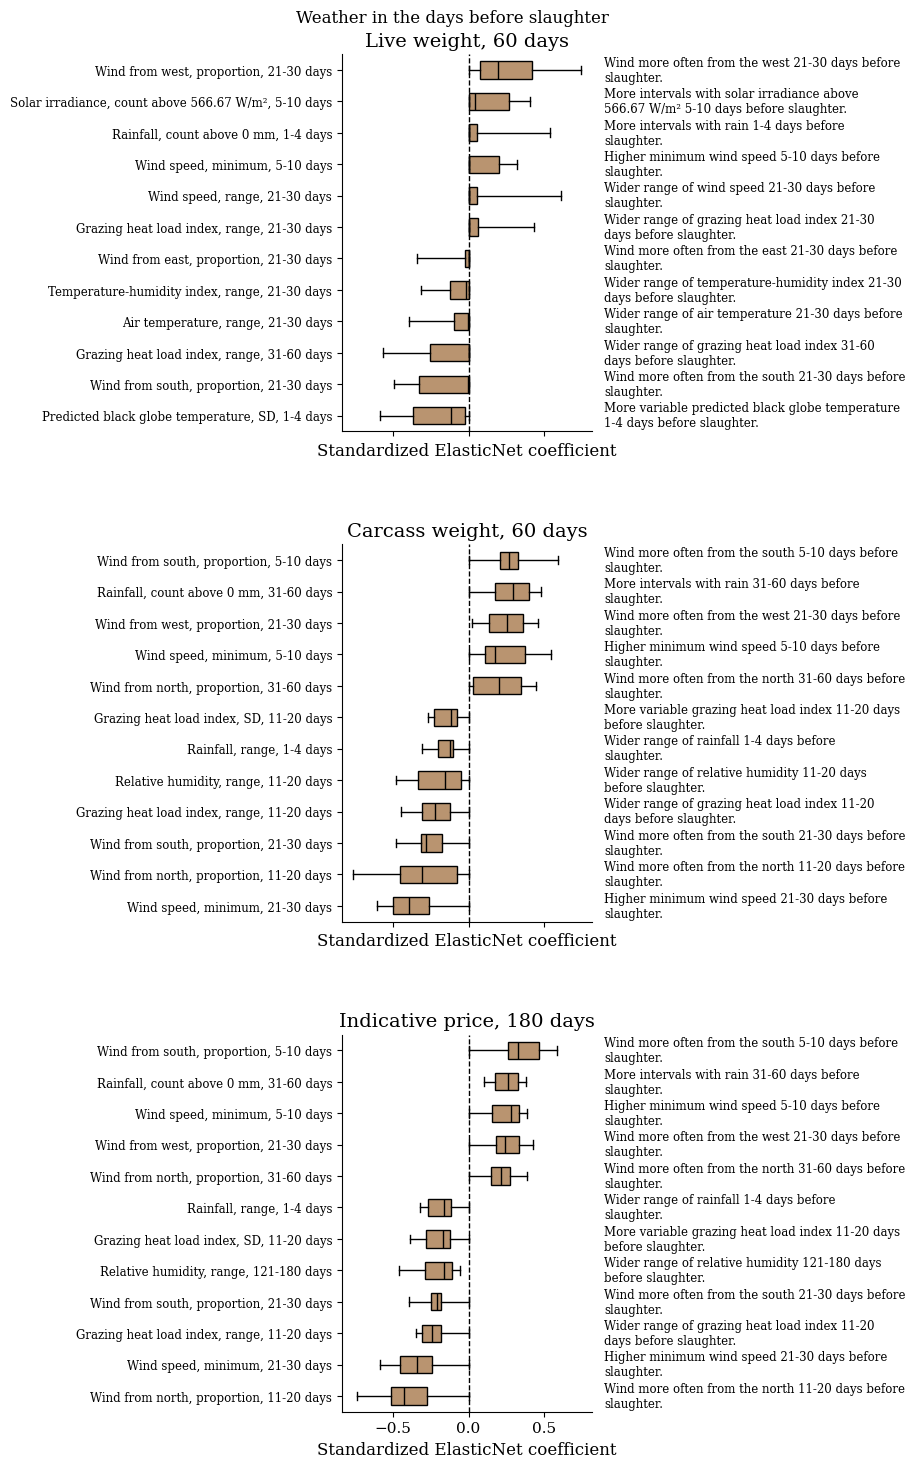

In [9]:
from textwrap import fill
coefficients = pd.read_csv(importance_dir / "importance_coefficients.csv")
coefficient_summary = coefficients.groupby(["panel", "feature"]).coefficient.agg(
    retained_folds="size", mean_coefficient="mean").reset_index()

weather_names = {"MnTemp(C)": "air temperature", "MnRH(%)": "relative humidity", "MnSpd(mps)": "wind speed",
                 "Rain(mm)": "rainfall", "RadGlb(MJ/m2)": "solar energy", "Average W/m2": "solar irradiance",
                 "Predicted BGT": "predicted black globe temperature", "THI": "temperature-humidity index",
                 "HLI": "heat load index", "Grazing HLI2": "grazing heat load index"}
units = {"MnTemp(C)": "°C", "Predicted BGT": "°C", "MnRH(%)": "%", "MnSpd(mps)": "m/s",
         "Rain(mm)": "mm", "Average W/m2": "W/m²", "RadGlb(MJ/m2)": "MJ/m²"}
directions = dict(zip("N NE E SE S SW W NW".split(), "north northeast east southeast south southwest west northwest".split()))

def explanation(feature):
    base, window, stat = re.fullmatch(r"(.+)__win(\d+_\d+)_(.+)", feature).groups()
    if stat == "proportion":
        label = f"Wind more often from the {directions[base[5:]]}"
    elif stat.startswith("above"):
        threshold = float(stat[5:-6])
        label = "More intervals with rain" if base == "Rain(mm)" and threshold == 0 else (
            f"More intervals with {weather_names[base]} above {threshold:g} {units.get(base, '')}".rstrip())
    else:
        phrase = {"max": "Higher peak", "min": "Higher minimum", "mean": "Higher average", "diff": "Wider range of", "std": "More variable"}
        label = f"{phrase[stat]} {weather_names[base]}"
    return fill(f"{label} {WINDOW_LABELS[window]} before slaughter.", width=48)

def feature_label(feature):
    base, window, stat = re.fullmatch(r"(.+)__win(\d+_\d+)_(.+)", feature).groups()
    if stat == "proportion":
        name, aggregation = f"Wind from {directions[base[5:]]}", "proportion"
    else:
        name = weather_names[base].capitalize()
        if stat.startswith("above"):
            aggregation = f"count above {float(stat[5:-6]):g} {units.get(base, '')}".rstrip()
        else:
            aggregation = {"min": "minimum", "max": "maximum", "mean": "mean", "std": "SD", "diff": "range"}[stat]
    return f"{name}, {aggregation}, {WINDOW_LABELS[window]}"

fig, axes = plt.subplots(3, 1, figsize=(10, 15), sharex=True)
for panel, ax in enumerate(axes):
    sub = coefficient_summary.query("panel == @panel and retained_folds >= 5")
    sub = sub.assign(magnitude=sub.mean_coefficient.abs()).nlargest(12, "magnitude").sort_values("mean_coefficient")
    folds = coefficients.loc[coefficients.panel.eq(panel)].pivot(index="fold", columns="feature", values="coefficient")
    ax.boxplot([folds[f].dropna() for f in sub.feature], positions=range(len(sub)), orientation="horizontal",
               widths=.55, whis=(0, 100), patch_artist=True, boxprops={"facecolor": PALETTE["steer"]},
               medianprops={"color": "black"})
    ax.set_yticks(range(len(sub)), sub.feature.map(feature_label), fontsize=8.5)
    for y, feature in enumerate(sub.feature):
        ax.text(1.05, y, explanation(feature), transform=ax.get_yaxis_transform(), va="center", fontsize=8.5)
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(title=PANEL_TITLES[panel], xlabel="Standardized ElasticNet coefficient")
    tidy(ax)

fig.suptitle("Weather in the days before slaughter")
fig.subplots_adjust(left=.39, right=.64, top=.95, bottom=.045, hspace=.3)
save(fig, "steer_elasticnet_elasticnet_signed_coefficients")
plt.show()